# Building Perceptron : partie théorique

**Projet La Plateforme : Initiation au Deep Learning**

## Introduction

Ce notebook rassemble la partie théorique du projet. Il répond à deux ensembles de questions :

1. **Initiation au Deep Learning** : définir et comparer Machine Learning et Deep Learning, puis présenter trois applications du Deep Learning.
2. **Dessine-moi un neurone artificiel** : comprendre le Perceptron de Frank Rosenblatt (définition, équation, règle d'apprentissage, fonction d'activation, entraînement, limites).

Les parties suivantes du notebook (implémentation de la classe `Perceptron`, puis application au jeu de données Breast Cancer Wisconsin) s'appuient sur les notions posées ici.

**Plan**
- 1. Machine Learning vs Deep Learning
- 2. Trois applications du Deep Learning
- 3. Le Perceptron (questions 1 à 6)

---
# 1. Machine Learning vs Deep Learning

## 1.1 Le Machine Learning

Le **Machine Learning** (apprentissage automatique) regroupe des méthodes dans lesquelles un algorithme **apprend des règles à partir de données** au lieu d'être programmé explicitement avec ces règles. Le modèle ajuste ses paramètres pour minimiser une erreur mesurée sur des exemples.

On distingue trois grandes familles :

- **L'apprentissage supervisé** : les données sont étiquetées (entrées $X$, cible $y$). Exemples : régression linéaire, régression logistique, arbres de décision, forêts aléatoires, SVM. C'est le cadre de ce projet (classification bénin / malin).
- **L'apprentissage non supervisé** : pas d'étiquettes, on cherche une structure dans les données (clustering avec k-means, réduction de dimensionnalité avec PCA).
- **L'apprentissage par renforcement** : un agent apprend par essais et récompenses.

Dans le Machine Learning classique, l'humain réalise souvent le **feature engineering** : il choisit et construit lui-même les variables les plus informatives.

## 1.2 Le Deep Learning

Le **Deep Learning** (apprentissage profond) est un sous-domaine du Machine Learning fondé sur les **réseaux de neurones artificiels comportant plusieurs couches cachées**. Chaque couche transforme la représentation produite par la précédente : les premières couches détectent des motifs simples (contours, sons élémentaires), les suivantes les combinent en concepts de plus en plus abstraits.

Sa particularité est que le réseau **apprend lui-même les caractéristiques utiles** à partir de données brutes (pixels, signal audio, texte), sans feature engineering manuel. L'entraînement repose sur la **descente de gradient** et la **rétropropagation** de l'erreur.

Relation d'inclusion : **Intelligence artificielle ⊃ Machine Learning ⊃ Deep Learning**.

## 1.3 Comparaison

| Critère | Machine Learning classique | Deep Learning |
|---|---|---|
| Volume de données | Fonctionne avec peu de données (centaines à milliers d'exemples) | Demande de grands volumes (dizaines de milliers à millions) |
| Feature engineering | Manuel, guidé par l'expertise métier | Automatique (apprentissage de représentations) |
| Type de données | Surtout tabulaires et structurées | Images, texte, audio, vidéo (données non structurées) |
| Calcul | CPU suffisant | GPU ou TPU généralement nécessaires |
| Temps d'entraînement | Court | Long |
| Interprétabilité | Plutôt bonne (modèles linéaires, arbres) | Faible (« boîte noire ») |
| Performance sur problèmes complexes | Plafonne | Très élevée avec assez de données |

## 1.4 Quand utiliser l'un plutôt que l'autre ?

**Privilégier le Machine Learning classique quand :**
- les données sont tabulaires et en quantité modeste ;
- l'explicabilité est importante (santé, finance, contexte réglementaire) ;
- les ressources de calcul sont limitées ou qu'il faut un prototype rapide.

**Privilégier le Deep Learning quand :**
- les données sont non structurées (images, voix, langage) ;
- le volume de données est important ;
- les caractéristiques pertinentes sont difficiles à décrire à la main ;
- les ressources de calcul sont disponibles.

**Règle pratique :** on commence par un modèle simple qui sert de référence (baseline). On ne passe au Deep Learning que si les performances sont insuffisantes et que les données et le calcul le permettent.

> Pour ce projet, le jeu de données Breast Cancer Wisconsin est tabulaire et ne contient que 569 observations : c'est un cas typique où le Machine Learning classique est adapté.

---
# 2. Trois applications du Deep Learning

## 2.1 Vision par ordinateur : imagerie médicale et conduite autonome

- **Problème** : analyser automatiquement des images (radiographies, lames histologiques, scènes routières).
- **Données** : images, c'est-à-dire des grilles de pixels.
- **Architecture** : réseaux de neurones convolutifs (CNN), qui détectent des motifs locaux puis les assemblent.
- **Exemples** : aide à la détection de tumeurs sur mammographies, détection de piétons et de panneaux par un véhicule autonome, reconnaissance de visages.
- **Limites** : besoin de grands jeux de données annotées, biais des données, difficulté à expliquer une décision, enjeux de sécurité et de vie privée.

## 2.2 Traitement du langage naturel : traduction et assistants conversationnels

- **Problème** : comprendre et produire du langage humain.
- **Données** : texte (séquences de mots ou de sous-mots).
- **Architecture** : Transformers, fondés sur le mécanisme d'attention. Ils sont à la base des grands modèles de langage comme ceux développés par OpenAI.
- **Exemples** : traduction automatique, résumé de documents, assistants conversationnels, aide à la rédaction de code.
- **Limites** : coût d'entraînement très élevé, réponses parfois erronées présentées avec assurance, biais issus des données d'entraînement.

## 2.3 Génération de contenu : images, voix et sciences

- **Problème** : créer de nouvelles données réalistes ou résoudre des problèmes scientifiques complexes.
- **Données** : paires texte-image, enregistrements audio, structures de protéines.
- **Architecture** : modèles de diffusion et réseaux antagonistes génératifs (GAN) pour les images, réseaux spécialisés pour la synthèse vocale ; AlphaFold pour la prédiction de la structure des protéines.
- **Exemples** : génération d'images à partir d'une description textuelle, clonage et synthèse de voix, prédiction du repliement de protéines pour la recherche pharmaceutique.
- **Limites** : risques de désinformation (deepfakes), questions de droits d'auteur, consommation énergétique.

*Sources d'inspiration : AI Experiments (Google) et OpenAI, comme suggéré dans le sujet.*

---
# 3. Le Perceptron

## Question 1 : Qu'est-ce qu'un Perceptron ? Quel lien avec un neurone biologique ?

Le **Perceptron** est le premier neurone artificiel à avoir été entraîné automatiquement. Il a été proposé par **Frank Rosenblatt en 1958**, à partir du neurone formel de McCulloch et Pitts (1943). C'est un **classifieur binaire linéaire** : il calcule une somme pondérée de ses entrées, ajoute un biais, puis décide de la classe (0 ou 1) selon un seuil.

**Analogie avec le neurone biologique :**

| Neurone biologique | Perceptron |
|---|---|
| Dendrites (reçoivent les signaux) | Entrées $x_1, \dots, x_n$ |
| Force des synapses | Poids $w_1, \dots, w_n$ |
| Corps cellulaire (agrège les signaux) | Somme pondérée + biais |
| Seuil de déclenchement du neurone | Fonction d'activation |
| Axone (transmet l'influx nerveux) | Sortie $\hat{y}$ |

Un neurone biologique « s'active » lorsque la somme des signaux reçus dépasse un seuil ; le Perceptron reproduit ce principe de façon très simplifiée. L'analogie est une **inspiration** : un vrai neurone est bien plus complexe (dynamique temporelle, plasticité, chimie des synapses).

## Question 2 : Fonction mathématique du Perceptron, usage et termes de l'équation

Le Perceptron calcule d'abord une **entrée nette** $z$, puis applique une fonction d'activation $f$ :

$$z = \sum_{i=1}^{n} w_i x_i + b = \mathbf{w} \cdot \mathbf{x} + b \qquad\qquad \hat{y} = f(z)$$

**Définition des termes :**

- $\mathbf{x} = (x_1, \dots, x_n)$ : vecteur des **entrées**, c'est-à-dire les variables d'un échantillon.
- $\mathbf{w} = (w_1, \dots, w_n)$ : vecteur des **poids**, un par entrée. Chaque poids mesure l'importance et le sens (positif ou négatif) de l'influence de la variable. Ce sont les paramètres que le modèle apprend.
- $b$ : le **biais**, qui décale le seuil de décision. Sans lui, la frontière de décision passerait forcément par l'origine.
- $z$ : l'**entrée nette** (combinaison linéaire des entrées).
- $f$ : la **fonction d'activation** (ici l'échelon).
- $\hat{y}$ : la **prédiction** du modèle, valant 0 ou 1.

**Usage :** classification binaire de données **linéairement séparables**. La frontière de décision est l'hyperplan d'équation $\mathbf{w} \cdot \mathbf{x} + b = 0$ : d'un côté le modèle prédit la classe 1, de l'autre la classe 0. En deux dimensions, c'est une droite.

## Question 3 : Règles d'apprentissage du Perceptron

### Règle du Perceptron (Rosenblatt)

Pour chaque exemple $(\mathbf{x}, y)$, on calcule la prédiction $\hat{y}$ puis on corrige les paramètres :

$$\mathbf{w} \leftarrow \mathbf{w} + \eta \,(y - \hat{y})\,\mathbf{x} \qquad\qquad b \leftarrow b + \eta \,(y - \hat{y})$$

où $\eta$ (eta) est le **taux d'apprentissage**, un petit réel positif qui règle la taille des corrections.

**Interprétation :**
- si $\hat{y} = y$, l'erreur est nulle et rien ne change ;
- si $y = 1$ et $\hat{y} = 0$, on **ajoute** $\eta\mathbf{x}$ aux poids, ce qui fait augmenter $z$ pour cet exemple ;
- si $y = 0$ et $\hat{y} = 1$, on **retire** $\eta\mathbf{x}$, ce qui fait diminuer $z$.

**Théorème de convergence :** si les données sont linéairement séparables, cette règle trouve un hyperplan séparateur en un nombre fini de mises à jour.

### Règle delta par descente de gradient (Adaline)

On définit une fonction de coût, par exemple l'erreur quadratique calculée sur l'entrée nette :

$$J(\mathbf{w}, b) = \frac{1}{2} \sum_{j} \left(y^{(j)} - z^{(j)}\right)^2$$

puis on met à jour les paramètres dans la direction opposée au gradient :

$$\mathbf{w} \leftarrow \mathbf{w} - \eta \,\frac{\partial J}{\partial \mathbf{w}} = \mathbf{w} + \eta \sum_{j} \left(y^{(j)} - z^{(j)}\right)\mathbf{x}^{(j)}$$

Cette approche est la base de l'entraînement des réseaux de neurones modernes. La différence avec la règle de Rosenblatt est que l'erreur est mesurée sur la valeur continue $z$ et non sur la sortie binaire après l'échelon.

## Question 4 : Fonction d'activation

Le Perceptron classique utilise la **fonction échelon de Heaviside** :

$$f(z) = \begin{cases} 1 & \text{si } z \geq 0 \\ 0 & \text{si } z < 0 \end{cases}$$

- **Avantage** : très simple, elle fournit directement une sortie binaire.
- **Inconvénient** : elle est non dérivable en 0 et sa dérivée est nulle partout ailleurs. Elle est donc inutilisable pour la descente de gradient appliquée à la sortie et pour la rétropropagation.

Les réseaux modernes la remplacent par des fonctions dérivables : **sigmoïde** (sortie entre 0 et 1, interprétable comme une probabilité), **tanh**, **ReLU** ($\max(0, z)$) ou **softmax** (cas multiclasse). Le graphique ci-dessous compare l'échelon à ces fonctions.

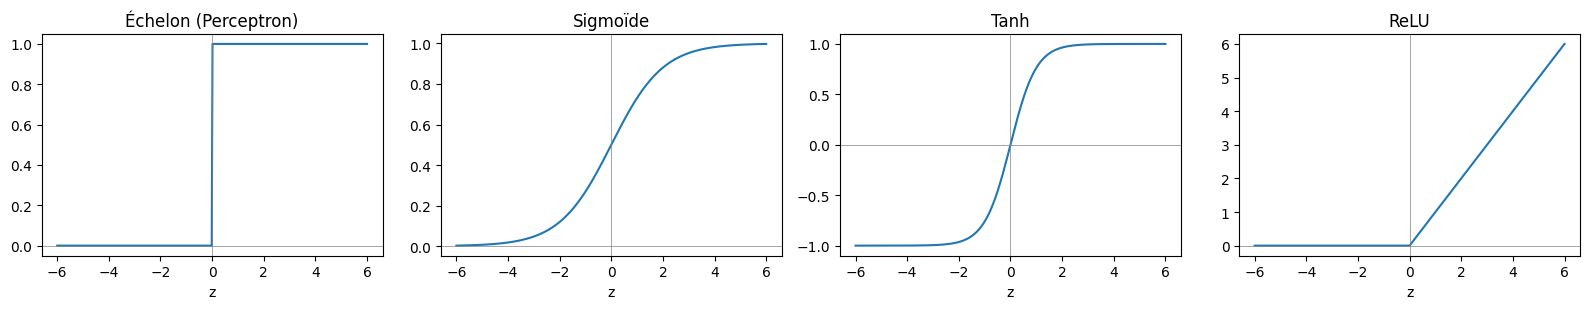

In [1]:
import numpy as np
import matplotlib.pyplot as plt

z = np.linspace(-6, 6, 400)
activations = {
    "Échelon (Perceptron)": np.where(z >= 0, 1, 0),
    "Sigmoïde": 1 / (1 + np.exp(-z)),
    "Tanh": np.tanh(z),
    "ReLU": np.maximum(0, z),
}

fig, axes = plt.subplots(1, 4, figsize=(16, 3.2), sharex=True)
for ax, (name, values) in zip(axes, activations.items()):
    ax.plot(z, values)
    ax.axhline(0, color="grey", lw=0.5)
    ax.axvline(0, color="grey", lw=0.5)
    ax.set_title(name)
    ax.set_xlabel("z")
plt.tight_layout()
plt.show()

**Interprétation :** l'échelon passe brutalement de 0 à 1 en $z = 0$ : la sortie est tranchée, sans nuance et sans pente exploitable. Les autres fonctions varient de façon continue, ce qui permet de calculer un gradient et donc d'entraîner des réseaux à plusieurs couches.

## Question 5 : Processus d'entraînement du Perceptron

L'entraînement consiste à ajuster $\mathbf{w}$ et $b$ pour que les prédictions correspondent aux étiquettes :

1. **Initialiser** les poids (à zéro ou avec de petites valeurs aléatoires) et le biais.
2. **Choisir** les hyperparamètres : taux d'apprentissage $\eta$ et nombre maximal d'époques.
3. **Pour chaque époque**, parcourir les exemples d'entraînement et, pour chacun :
   - calculer l'entrée nette $z = \mathbf{w} \cdot \mathbf{x} + b$ ;
   - appliquer l'activation pour obtenir $\hat{y}$ ;
   - calculer l'erreur $y - \hat{y}$ ;
   - mettre à jour $\mathbf{w}$ et $b$ avec la règle d'apprentissage.
4. **Compter les erreurs** de l'époque pour suivre la convergence.
5. **S'arrêter** quand une époque se termine sans aucune erreur, ou quand le nombre maximal d'époques est atteint.
6. **Évaluer** le modèle sur un jeu de test que l'entraînement n'a jamais vu.

**Bonnes pratiques :**
- **mélanger** les exemples à chaque époque pour éviter qu'un ordre particulier biaise l'apprentissage ;
- **standardiser** les variables, sinon celles de grande échelle dominent la somme pondérée ;
- **séparer** train et test avant tout prétraitement qui apprend à partir des données (standardisation, sélection de variables), afin d'éviter les fuites de données.

## Question 6 : Limites du Perceptron

- **Séparabilité linéaire uniquement.** Le Perceptron ne peut tracer qu'une frontière linéaire. Il est incapable d'apprendre la fonction **XOR**, ce que Minsky et Papert ont démontré en 1969, ce qui a contribué au premier « hiver de l'IA ».
- **Pas de convergence sur des données non séparables.** Les poids oscillent indéfiniment et le nombre d'erreurs ne tombe jamais à zéro. Il faut alors borner le nombre d'époques.
- **Sortie binaire dure.** Pas de probabilité, donc pas de mesure de confiance et pas de seuil ajustable (problématique en contexte médical, où l'on souhaite parfois privilégier la détection des cas positifs).
- **Classification binaire uniquement.** Le multiclasse demande plusieurs perceptrons, par exemple en stratégie un-contre-tous.
- **Sensibilité à l'échelle des variables, au bruit et aux valeurs aberrantes.**
- **Solution non unique.** Plusieurs hyperplans peuvent séparer les données, sans critère de marge (à l'inverse du SVM).

**Illustration : la table de vérité du XOR**

| $x_1$ | $x_2$ | XOR |
|---|---|---|
| 0 | 0 | 0 |
| 0 | 1 | 1 |
| 1 | 0 | 1 |
| 1 | 1 | 0 |

Aucune droite ne sépare les points de classe 1 ((0,1) et (1,0)) de ceux de classe 0 ((0,0) et (1,1)). Ce cas sera testé avec notre implémentation dans la partie suivante.

**Dépassement des limites :** perceptron multicouche (MLP) avec activations non linéaires, régression logistique (sortie probabiliste), SVM à noyau.

---
### Transition

Les notions de cette partie (équation $\hat{y} = f(\mathbf{w}\cdot\mathbf{x}+b)$, règle de mise à jour, activation échelon, boucle d'entraînement par époques) sont exactement celles qui seront codées dans la classe `Perceptron` de la partie suivante.